## Datasets and Inputs
- **Upstream & Downstream miniDOT Logger Data:** Battery voltage, water temperature, DO concentration (mg/L), DO percent saturation, and measurement quality indicator. **Target variable:** downstream DO (mg/L).
- **Water Level Time Series (Pressure Gauges):** Upstream and downstream water surface elevations referenced to the **IGM40** datum (elevation above datum, *not* water depth).
- **Combined Sewer / Sub-Basin Characteristics:** Characteristics of urban sub-basins discharging combined sewer inputs between the upstream and downstream sections.
- **Discharge & Water Level Measurements:** Field discharge measurements near the monitoring stations paired with corresponding water levels (for rating/hydraulic relationship estimation).
- **Canal Bed Elevation Profiles:** Cross-sectional bed elevations at the monitoring sections from Acoustic Doppler Profilers (ADCP), used alongside IGM40 water levels to derive water depth/geometry.
- **`arpav_padua station.xlsx`:** Precipitation and global solar radiation time series from the ARPAV station in Padua.
- **`MAP_canal network_stations.png`:** Hydrographic map of the Padua canal network showing monitoring station locations.

## Modelling Workflow 
1. **Conceptualization and Data Pre-processing:** Align timestamps, inspect measurement quality flags, convert IGM40 water levels and ADCP bed profiles into hydraulic variables (depth, cross-sectional area, volume/travel time), and integrate meteorological and combined sewer inputs.
2. **Version 1 — 1-State Model (DO):** Simulates downstream DO dynamics accounting for upstream DO advection/transport, atmospheric reaeration, photosynthesis/respiration (linked to solar radiation/temperature where applicable), and external/benthic/sewer sinks.
3. **Version 2 — 2-State Model (DO + BOD):** Adds organic matter / BOD dynamics alongside DO, capturing oxygen consumption driven by BOD decay and combined sewer discharges.
4. **Model Assessment & Comparison:** Evaluate calibration and validation fit (e.g., RMSE, MAE, Nash-Sutcliffe Efficiency / $R^2$) alongside model complexity (number of state variables and calibrated parameters, parsimony, and identifiability).

1. Define the Control Volume and Inspect Station LayoutOpen MAP_canal network_stations.png to identify the upstream station, downstream station, flow direction, and any sub-basins or combined sewer outfalls discharging between them.Confirm which section's miniDOT DO ($\text{mg/L}$) series is your target output for calibration and validation.List every input file in data/ and verify units, column headers, and timestamps before merging.
2. Clean miniDOT Logger and ARPAV Time SeriesParse timestamps into a single timezone-aware datetime index (check whether logger timestamps and arpav_padua station.xlsx use local time or UTC).Filter or flag miniDOT rows using the measurement quality indicator, and check battery voltage or temperature anomalies that could signal sensor drift or fouling.Resample or align irregular/different sampling intervals across upstream DO, upstream temperature, downstream DO, precipitation, and global solar radiation onto a common time grid (documenting any interpolation or aggregation choice).Inspect missing-data gaps and decide whether to mask gaps during model evaluation or interpolate short intervals.
3. Convert IGM40 Elevations and ADCP Profiles into HydraulicsRemember that pressure gauge series give water surface elevation relative to the IGM40 datum, not water depth above the bed.Pair each station's IGM40 water level time series with its ADCP cross-sectional bed elevation profile to derive water depth, wetted cross-sectional area, and hydraulic geometry/reach volume over time.Fit or inspect the stage-discharge relationship using the field discharge measurements and corresponding water levels near the monitoring stations so flow rates/advection times between upstream and downstream are grounded in your data.
4. Map Sub-Basin and Combined Sewer InputsReview the characteristics of the urban sub-basins draining between the upstream and downstream sections alongside ARPAV precipitation data.Determine how lateral/combined sewer inflows and organic/DO loads enter the canal reach (for example, dry-weather base flow versus rain-driven combined sewer overflows).
5. Set Up a Clean Python Preprocessing Script or NotebookKeep raw files untouched in data/ and save cleaned, aligned analysis tables or intermediates locally (ignored in Git) or inside a notebook/module under notebooks/ or src/.Save a clean summary table of date ranges, sampling intervals, missing percentages, and derived hydraulic variables so both the 1-state DO and 2-state DO–BOD models use the exact same preprocessed inputs.

In [10]:
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt

In [9]:
Precip = pd.ExcelFile("data/arpav_padua station.xlsx")
Canals = pd.ExcelFile("data/TM-PIO_2.xlsx")

df1 = pd.read_excel(Canals, "miniDOT", header=4, usecols="B:G,J:O", parse_dates=["Time","Time.1"])
df1

,Time,Battery,Temperature,DO,DO_perc,Q,Time.1,Battery.1,Temperature.1,DO.1,DO_perc.1,Q.1
0,2024-05-06 15:51:00,3.53,15.872,8.086,81.700336,0.978,2024-05-06 15:04:00,3.41,16.390,7.970,81.416429,0.933
1,2024-05-06 15:56:00,3.53,15.820,8.098,81.731104,0.979,2024-05-06 15:09:00,3.41,16.365,7.984,81.516460,0.933
2,2024-05-06 16:01:00,3.53,15.786,8.107,81.762724,0.979,2024-05-06 15:14:00,3.41,16.314,7.963,81.214607,0.933
3,2024-05-06 16:06:00,3.53,15.761,8.111,81.759510,0.979,2024-05-06 15:19:00,3.41,16.228,7.972,81.158819,0.933
4,2024-05-06 16:11:00,3.53,15.761,8.110,81.749430,0.979,2024-05-06 15:24:00,3.41,16.143,8.074,82.049554,0.933
...,...,...,...,...,...,...,...,...,...,...,...,...
34635,NaT,NaN,NaN,NaN,NaN,NaN,2024-09-03 23:36:00,3.32,22.921,5.869,68.318917,0.924
34636,NaT,NaN,NaN,NaN,NaN,NaN,2024-09-03 23:41:00,3.32,22.879,5.804,67.508390,0.924
34637,NaT,NaN,NaN,NaN,NaN,NaN,2024-09-03 23:46:00,3.32,22.879,5.764,67.043135,0.925
34638,NaT,NaN,NaN,NaN,NaN,NaN,2024-09-03 23:51:00,3.32,22.879,5.733,66.682563,0.924


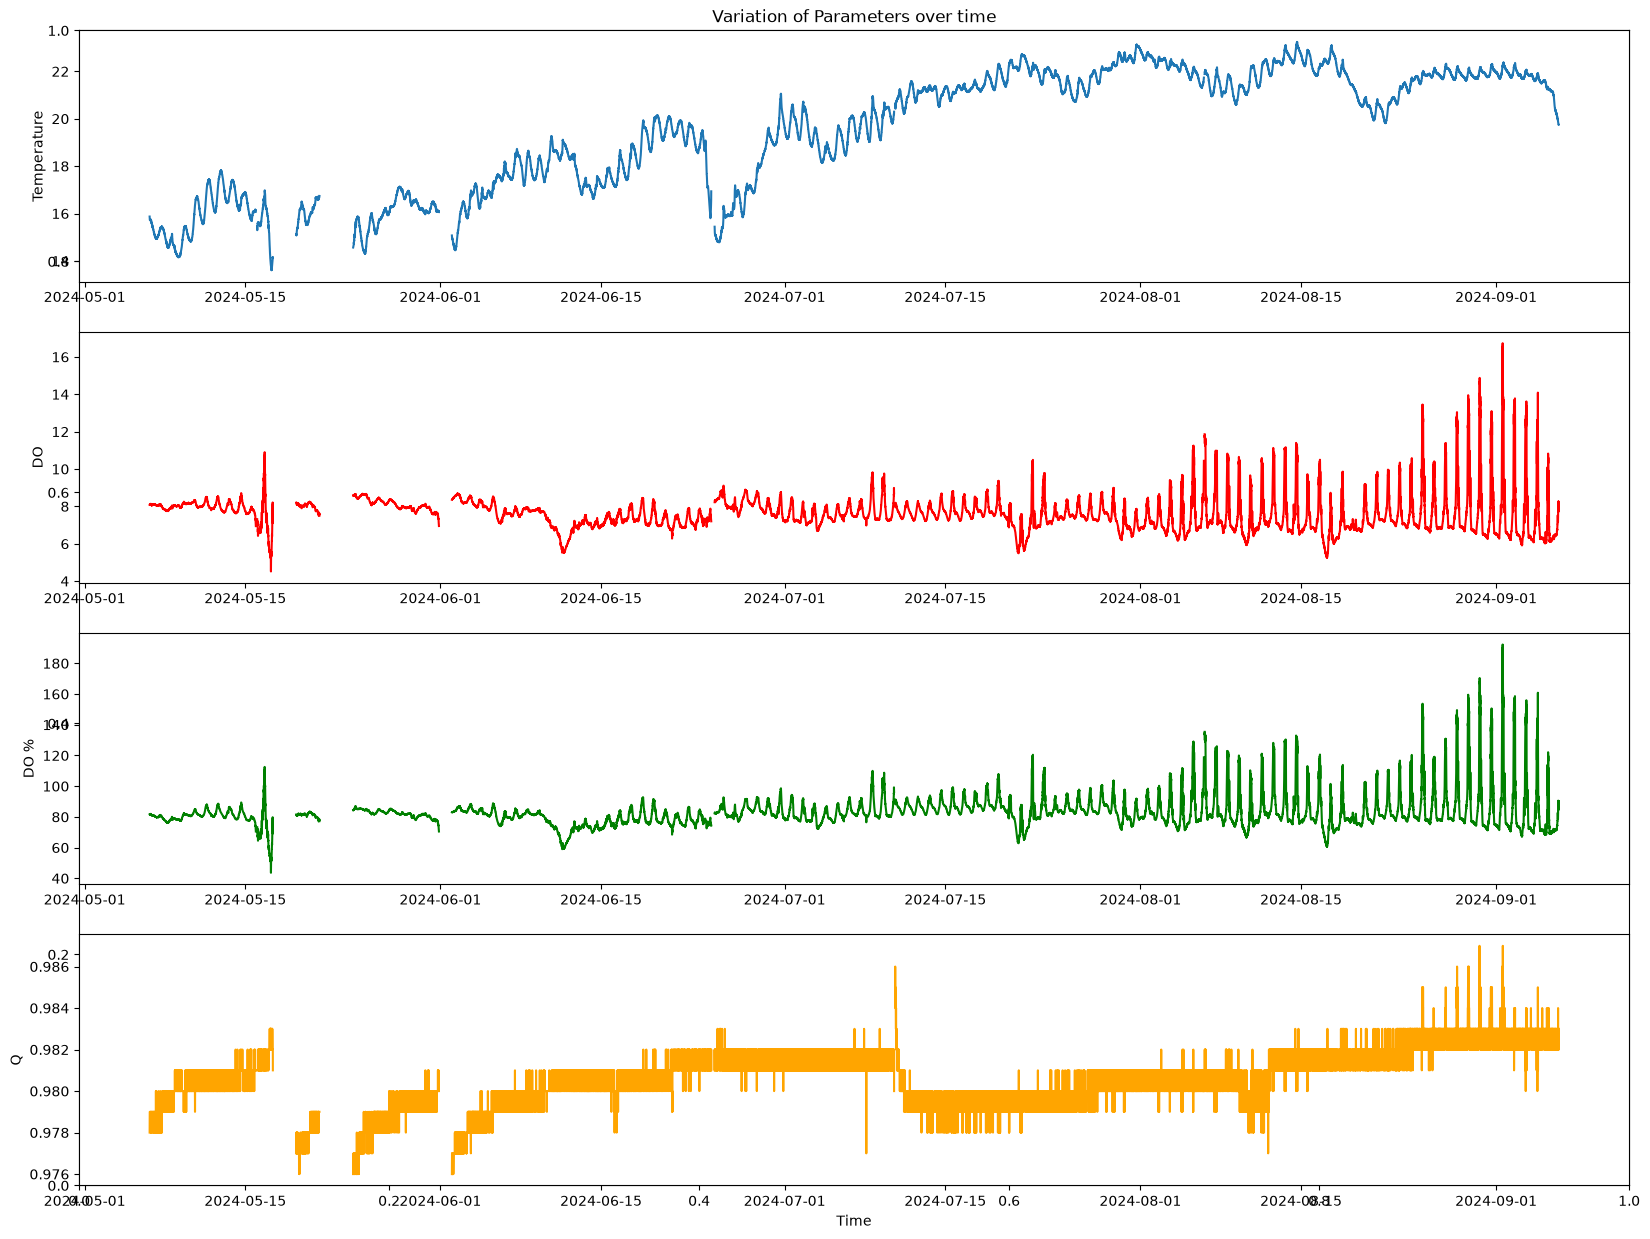

In [32]:
plt.figure(figsize=(20, 15))
plt.title('Variation of Parameters over time')
plt.xlabel('Time')
plt.subplot(411)
plt.plot(df1['Time'], df1['Temperature'], data = df1)
plt.ylabel('Temperature')
plt.subplot(412)
plt.plot(df1['Time'], df1['DO'], data = df1, c='red')
plt.ylabel('DO')
plt.subplot(413)
plt.plot(df1['Time'], df1['DO_perc'], data = df1, c='green')
plt.ylabel('DO %')
plt.subplot(414)
plt.plot(df1['Time'], df1['Q'], data = df1, c='orange')
plt.ylabel('Q')
plt.show()